# Week 10: Simulation-based power and experimental design

A company is piloting an **AI-assisted training program** for customer-support
employees. We want to know, *before running the real experiment*, how likely we
are to detect a training benefit that we believe exists — and how to design the
experiment to detect it without overspending.

| Part | Question | Tool |
|---|---|---|
| 1 | When does a formula tell us the truth about power, and when do we need to simulate? | Analytical vs. simulated power |
| 2 | Is the most statistically powerful design also the cheapest? | Cost vs. power trade-off |
| 3 | Which of many candidate designs is actually worth running? | Grid sweep + Pareto frontier |

**Scenario and notation** (illustrative assumptions, not real company data):

- Outcome $Y$: issues resolved per employee per week. Baseline mean $40$.
- Binary treatment $X$: $1$ = trained, $0$ = control, assigned at random.
- Assumed true training benefit: $\beta = +2$ issues/week — we don't know this is
  true; it's the effect we're planning *around*.
- Design choices: $n$ (total employees) and $p$ (fraction trained).
- Cost: **\$100** to recruit/measure each employee, **plus \$500** to train each
  treated employee. $\text{cost} = 100n + 500 \, n_{\text{treated}}$.
- Test: two-sided $H_0: \beta = 0$ at $\alpha = 0.05$. Target planning power:
  **80%** — a practical benchmark, not a law of nature.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, ttest_ind

pd.set_option("display.precision", 3)
TREAT, CTRL, GREY, INK, PARETO = "#D9822B", "#1B5AA6", "#999999", "#333333", "#2E8B57"

# Pastel colors
NON_REJECT = "#F4B8B8"  # Pastel red
REJECT = "#A8DDB5"      # Pastel green




BASELINE = 40.0
BETA = 2.0
CONFIDENCE = 0.95

SEED = 702
rng = np.random.default_rng(SEED)

## Part 1 — Analytical power vs. simulated power

### A. One simple study, then many simulated studies

**Simple DGP:** $Y = 40 + 2X + \varepsilon$, where $\varepsilon \sim N(0, 5^2)$.

Default design: 200 employees, with 100 assigned to training and 100 to control.

**Analytical power**

Under the simple DGP, the estimated treatment coefficient follows a normal distribution:

$$
\hat\beta \sim N(\beta, SE^2)
$$

where

$$
SE = \sigma\sqrt{\frac{1}{n_{\text{treated}}}+\frac{1}{n_{\text{control}}}}
$$

We can calculate statistical power directly from this distribution:

- Under the null hypothesis ($\beta=0$), identify the region containing 95% of estimated coefficients: $[-1.96SE,\;1.96SE]$.
- Under the assumed true effect ($\beta=2$), calculate the probability that $\hat\beta$ falls **outside** this region.
- That probability is the analytical statistical power.

**Simulation-based power**

Now estimate the same quantity computationally:

1. Generate many datasets using the assumed DGP.
2. Estimate the treatment coefficient for each dataset.
3. Check whether $|\hat\beta| > 1.96SE$.
4. Calculate the fraction of experiments that reject the null.

The analytical and simulated power estimates should be approximately equal.

**Why use 1.96?** We are using a two-sided hypothesis test with a 5% significance level, and the noise variance is assumed known. In practice, we usually estimate the standard error and use a t-test, but this simplified setting lets us compare the analytical calculation and simulation directly.

In [2]:

N_DEFAULT = 200
P_DEFAULT = 0.50
SD_SIMPLE = 5.0

n_treated = int(round(N_DEFAULT * P_DEFAULT))
n_control = N_DEFAULT - n_treated

# Standard deviation of the estimated treatment coefficient
se = SD_SIMPLE * np.sqrt(1 / n_treated + 1 / n_control)

# Rejection boundaries under the null hypothesis (beta = 0)
alpha = 1.0-CONFIDENCE
z_critical = norm.ppf(1 - alpha / 2)

print(f"z_critical: {z_critical:.3f}")

threshold = z_critical * se



# Probability of falling outside those boundaries
# when the true treatment effect is BETA
power = (
    norm.cdf(-threshold, loc=BETA, scale=se)
    + 1.0-norm.cdf(threshold, loc=BETA, scale=se)
)

print(f"SE = {se:.3f}")
print(f"Non-rejection region: [{-threshold:.3f}, {threshold:.3f}]")
print(f"Analytical power = {power:.3f}")


analytical_power_simple = power


z_critical: 1.960
SE = 0.707
Non-rejection region: [-1.386, 1.386]
Analytical power = 0.807


**Rejection region.** Under the null hypothesis ($\beta=0$), the estimated coefficient follows a normal distribution centered at zero, with standard deviation $SE$.

For a two-sided test with a 5% significance level, 95% of estimates fall within $[-1.96SE,\,+1.96SE]$.

We reject the null hypothesis when our estimate falls outside this region.

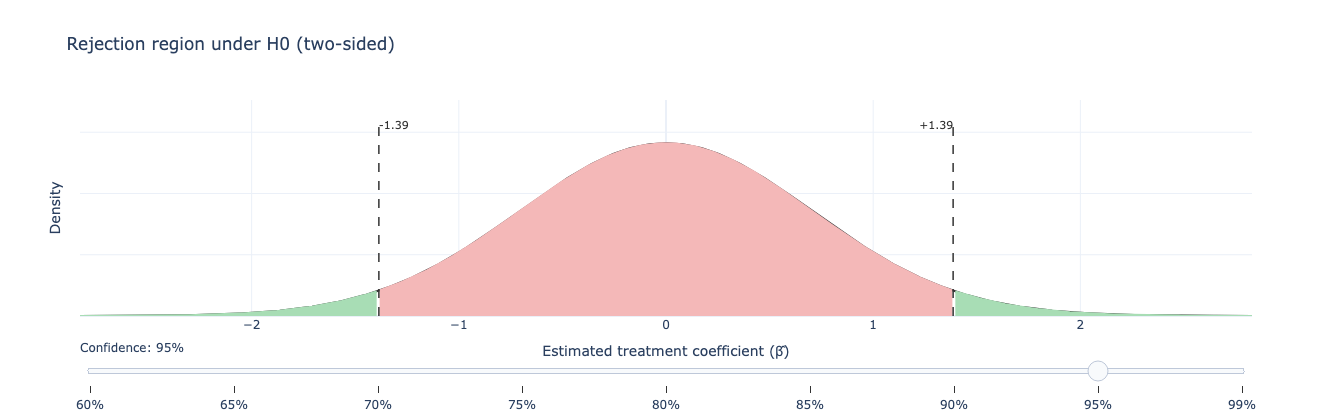

In [89]:
import plotly.graph_objects as go

# Compute distribution and thresholds once
beta_grid = np.linspace(-4 * se, 4 * se, 400)
density = norm.pdf(beta_grid, loc=0, scale=se)

confidence_values = [0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99]
initial_confidence = 0.95

thresholds = {
    c: norm.ppf((1 + c) / 2) * se
    for c in confidence_values
}

def region_traces(confidence):
    threshold = thresholds[confidence]
    traces = []

    # Shaded regions
    for mask, color, name in [
        (beta_grid <= -threshold, REJECT, "Reject H0"),
        (np.abs(beta_grid) <= threshold, NON_REJECT, "Fail to reject H0"),
        (beta_grid >= threshold, REJECT, "Reject H0")
    ]:
        traces.append(go.Scatter(
            x=beta_grid[mask],
            y=density[mask],
            fill="tozeroy",
            mode="lines",
            line=dict(color=color),
            fillcolor=color,
            name=name
        ))

    # Vertical dashed lines and threshold labels
    for boundary, position in [
        (-threshold, "middle right"),  # Label left of line
        (threshold, "middle left")     # Label right of line
    ]:
        traces.append(go.Scatter(
            x=[boundary, boundary],
            y=[0, density.max() * 1.1],
            mode="lines",
            line=dict(color=INK, dash="dash", width=1.5),
            showlegend=False,
            hoverinfo="skip"
        ))

        traces.append(go.Scatter(
            x=[boundary],
            y=[density.max() * 1.1],
            mode="text",
            text=[f"{boundary:+.2f}"],
            textposition=position,
            textfont=dict(color=INK, size=11),
            showlegend=False,
            hoverinfo="skip"
        ))

    return traces


fig = go.Figure()

# Fixed null distribution
fig.add_trace(go.Scatter(
    x=beta_grid,
    y=density,
    mode="lines",
    line=dict(color=INK, width=2),
    name="Null distribution"
))

# Initial shaded regions and thresholds
fig.add_traces(region_traces(initial_confidence))

# Slider updates existing traces
steps = []

for confidence in confidence_values:
    traces = region_traces(confidence)

    steps.append(dict(
        method="update",
        args=[
            {
                "x": [beta_grid] + [t.x for t in traces],
                "y": [density] + [t.y for t in traces],
                "text": [None] + [t.text for t in traces]
            },
            {
                "title": (
                    f"Rejection region under H0 "
                    f"(α={1-confidence:.2f}, two-sided)"
                )
            }
        ],
        label=f"{confidence:.0%}"
    ))

fig.update_layout(
    title="Rejection region under H0 (two-sided)",
    xaxis_title="Estimated treatment coefficient (β̂)",
    yaxis=dict(
        title="Density",
        showticklabels=False,
        range=[0, density.max() * 1.25]
    ),
    sliders=[dict(
        active=confidence_values.index(initial_confidence),
        currentvalue={"prefix": "Confidence: "},
        steps=steps
    )],
    template="plotly_white",
    height=420,
    showlegend=False
)

fig.show()

In [8]:

N_SIMS_1A = 20_000


n_control_0 = n_control
n_treated_0 = n_treated

# Generate employee outcomes across simulated experiments
# Y
control = rng.normal(BASELINE, SD_SIMPLE, size=(N_SIMS_1A, n_control_0))
treated = rng.normal(BASELINE + BETA, SD_SIMPLE, size=(N_SIMS_1A, n_treated_0))

# Estimate the treatment coefficient in each experiment
beta_hats = treated.mean(axis=1) - control.mean(axis=1)

print(beta_hats.mean())

# Rejection boundaries under H0: beta = 0
threshold = z_critical * se

# LIVE CODING: reject if the estimated coefficient falls outside the region
simulated_power_simple = ((beta_hats < -threshold) | (beta_hats > threshold)).mean()

print(f"Simulated power = {simulated_power_simple:.3f}")
print(f"Analytical power = {analytical_power_simple:.3f}")


2.0024625465695847
Simulated power = 0.810
Analytical power = 0.807


The analytical and simulated power estimates should be close. They use the same assumptions and answer the same question.

### B. Change the DGP, not the formula

Suppose the training program works differently for different employees. Some benefit substantially, while others benefit very little.

We can represent these differences using an interaction term:

$$
Y = 40 + 2X + 2XZ + \varepsilon
$$

Here, $Z$ represents individual differences in how employees respond to training. Assume $Z\sim N(0,1)$, independent of treatment, and $\varepsilon\sim N(0,5^2)$.

If we estimate the simpler model $Y\sim X$, the omitted interaction becomes part of the error:

- **Control ($X=0$):** Error variance = $25$.
- **Treatment ($X=1$):** Error variance = $25+4=29$.

The error variances are now different across groups. This is **heteroskedasticity**.

Our original analytical formula assumes equal error variances, so it no longer matches the DGP. We can instead simulate experiments under the new DGP and use Welch's t-test, which allows unequal variances.

Analytical methods for unequal variances also exist. Our goal is to see how simulation lets us evaluate a changed DGP without deriving another formula.

In [9]:

SD_CONTROL = 5.0
SD_TREATED = 10.0
N_SIMS_1B = 20_000

# Step 1: Simulate under H0 (no treatment effect)
control_null = rng.normal(
    BASELINE, SD_CONTROL, size=(N_SIMS_1B, n_control_0)
)
treated_null = rng.normal(
    BASELINE, SD_TREATED, size=(N_SIMS_1B, n_treated_0)
)

beta_hats_null = treated_null.mean(axis=1) - control_null.mean(axis=1)

print(beta_hats_null.mean())

# Find rejection boundaries under H0 (based on confidence)
confidence = 0.95
alpha = 1.0-confidence
lower, upper = np.quantile(beta_hats_null, [alpha/2,1.0 - alpha/2])


# Step 2: Simulate under H1 (true treatment effect = BETA)
control_alt = rng.normal(
    BASELINE, SD_CONTROL, size=(N_SIMS_1B, n_control_0)
)
treated_alt = rng.normal(
    BASELINE + BETA, SD_TREATED, size=(N_SIMS_1B, n_treated_0)
)

beta_hats_alt = treated_alt.mean(axis=1) - control_alt.mean(axis=1)

print(beta_hats_alt.mean())

# Step 3: Estimate power using the rejection boundaries from H0
reject = (beta_hats_alt < lower) | (beta_hats_alt > upper)
simulated_power_hetero = reject.mean()

print(f"Null rejection region: beta_hat < {lower:.3f} or > {upper:.3f}")
print(f"Original analytical power = {analytical_power_simple:.3f}")
print(f"Simulated power (heteroskedastic DGP) = {simulated_power_hetero:.3f}")


-0.000892801561328707
1.9979248466055792
Null rejection region: beta_hat < -2.173 or > 2.186
Original analytical power = 0.807
Simulated power (heteroskedastic DGP) = 0.436


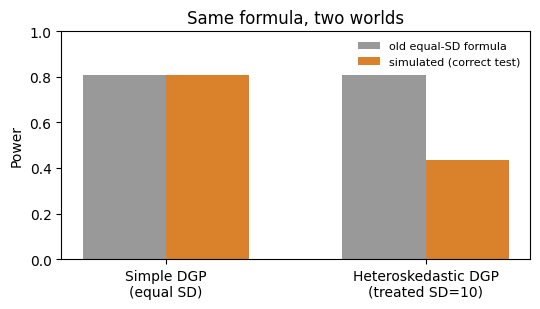

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
labels = ["Simple DGP\n(equal SD)", "Heteroskedastic DGP\n(treated SD=10)"]
analytical_vals = [analytical_power_simple, analytical_power_simple]
simulated_vals = [simulated_power_simple, simulated_power_hetero]
x = np.arange(2)
width = 0.32
ax.bar(x - width / 2, analytical_vals, width, label="old equal-SD formula", color=GREY)
ax.bar(x + width / 2, simulated_vals, width, label="simulated (correct test)", color=TREAT)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Power")
ax.set_title("Same formula, two worlds")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## Part 2 — Balancing cost and statistical power

We now turn to experimental design. We'll keep the heteroskedastic DGP from Part 1B (control SD = 5, treated SD = 10) and consider two decisions:

- **Sample size ($n$):** How many employees should participate?
- **Treatment share ($p$):** What fraction of employees should receive training?

Each employee costs 100 USD to recruit and measure, and training costs an additional 500 USD per employee.

- **Sample size:** More employees generally increase statistical power, but also increase costs.
- **Treatment share:** A 50/50 split may not maximize power because trained employees have more variable outcomes.
- **Training costs:** Training more employees increases costs, creating another reason to consider unequal allocation.

Our goal is to explore how these decisions affect both **power and total cost**.



In [11]:
RECRUIT_COST = 100
TRAIN_COST = 500


def total_cost(n, n_treated, recruit_cost=RECRUIT_COST, train_cost=TRAIN_COST):
    return recruit_cost * n + train_cost * n_treated


def simulate_power(n_treated, n_control, beta, baseline, sd_control, sd_treated, confidence, n_sims, rng):
    control_null = rng.normal(baseline, sd_control, size=(n_sims,n_control))
    treated_null = rng.normal(baseline, sd_treated, size=(n_sims,n_treated))

    beta_hats_null = treated_null.mean(axis=1) - control_null.mean(axis=1)

    alpha = 1.0-confidence
    
    lower,upper = np.quantile(beta_hats_null, [alpha/2,1.0 - alpha/2])

    control_alt = rng.normal(baseline, sd_control, size=(n_sims,n_control))
    treated_alt = rng.normal(baseline + beta, sd_treated, size=(n_sims,n_treated))

    beta_hats_alt = treated_alt.mean(axis=1) - control_alt.mean(axis=1)
    
    power = ((beta_hats_alt < lower) | (beta_hats_alt > upper)).mean()

    return power

candidate_designs = [
    dict(n=200, p=0.50),
    dict(n=200, p=0.25),
    dict(n=280, p=0.25),
]

N_SIMS_PART2 = 20_000
rows = []
for design in candidate_designs:
    n, p = design["n"], design["p"]
    n_treated = int(round(n * p))
    n_control = n - n_treated
    cost = total_cost(n, n_treated)
    power = simulate_power(n_treated, n_control, BETA, BASELINE, SD_CONTROL, SD_TREATED,
                            CONFIDENCE, N_SIMS_PART2, rng)
    rows.append(dict(n=n, p_target=p, n_treated=n_treated, n_control=n_control,
                      actual_p=n_treated / n, cost=cost, power=power))

part2_table = pd.DataFrame(rows)
part2_table

,n,p_target,n_treated,n_control,actual_p,cost,power
0,200,0.50,100,100,0.50,70000,0.424
1,200,0.25,50,150,0.25,45000,0.278
2,280,0.25,70,210,0.25,63000,0.367


## Part 3 — Exploring the Design Space

So far, we've examined how sample size and treatment allocation affect statistical power and cost. But which experimental designs offer the best trade-offs?

In this part, we'll explore a larger set of designs by varying both the sample size ($n$) and treatment share ($p$).

### A. Sweeping the Design Space

We'll simulate power across different combinations of $(n,p)$ and compare their costs.

Our goal is to identify:

- **Optimal designs:** Designs on the cost–power frontier, where improving power requires spending more.
- **Suboptimal designs:** Designs for which another option offers at least as much power at a lower cost, or more power at the same cost.

### B. Working with a Limited Simulation Budget

Simulating every design is feasible here, but more complex experiments may require expensive data generation or model fitting.

Suppose we can evaluate only **50 designs**. How should we choose them?

We'll compare two approaches:

- **Random sampling:** Select designs randomly from the search space.
- **Analytical guidance:** Use the simpler analytical power formula from Part 1 to prioritize promising candidates.

We'll examine whether analytical guidance helps us discover better cost–power trade-offs with fewer simulations.

In [65]:
N_VALUES = np.arange(10, 1001, 25)
P_VALUES = np.arange(0.10, 0.91, 0.05)

grid_rows = []
for n in N_VALUES:
    for p in P_VALUES:
        n_treated = int(round(n * p))
        n_control = n - n_treated
        grid_rows.append(dict(n=n, p_target=p, n_treated=n_treated, n_control=n_control,
                               actual_p=n_treated / n, cost=total_cost(n, n_treated)))

grid = pd.DataFrame(grid_rows)
print(f"{len(grid)} candidate designs")

680 candidate designs


In [14]:
# we will run 4000 simulations for each design point

results = grid.copy()

results["power"] = results.apply(
    lambda row: simulate_power(
        int(row["n_treated"]),
        int(row["n_control"]),
        BETA, BASELINE, SD_CONTROL, SD_TREATED,
        CONFIDENCE, 4000, rng
    ),
    axis=1
)

In [ ]:
# Compute the Pareto frontier
sorted_results = results.sort_values(
    ["cost", "power"], ascending=[True, False]
)

frontier = sorted_results[
    sorted_results["power"] >
    sorted_results["power"].cummax().shift(fill_value=-float("inf"))
]


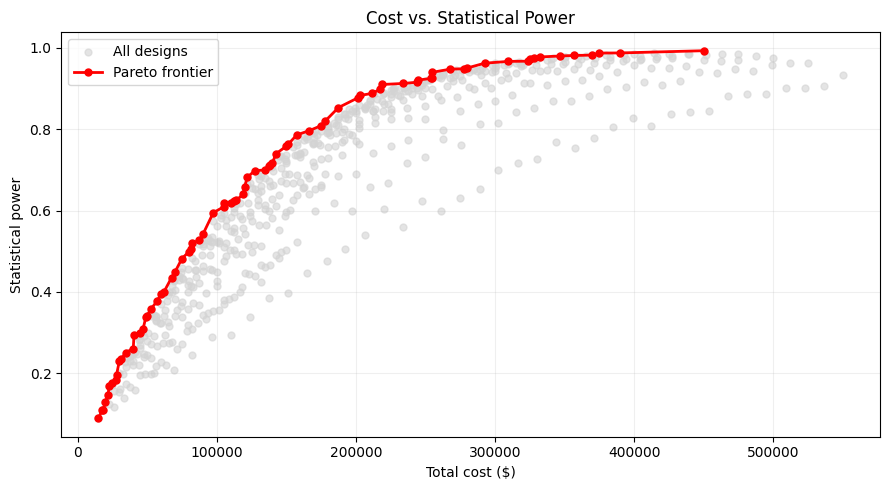

In [78]:
# Visualize all designs and the Pareto frontier
plt.figure(figsize=(9, 5))

plt.scatter(
    results["cost"], results["power"],
    color="lightgray", alpha=0.6, s=25,
    label="All designs"
)

plt.plot(
    frontier["cost"], frontier["power"],
    color="red", marker="o", markersize=5,
    linewidth=2, label="Pareto frontier"
)

plt.xlabel("Total cost ($)")
plt.ylabel("Statistical power")
plt.title("Cost vs. Statistical Power")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

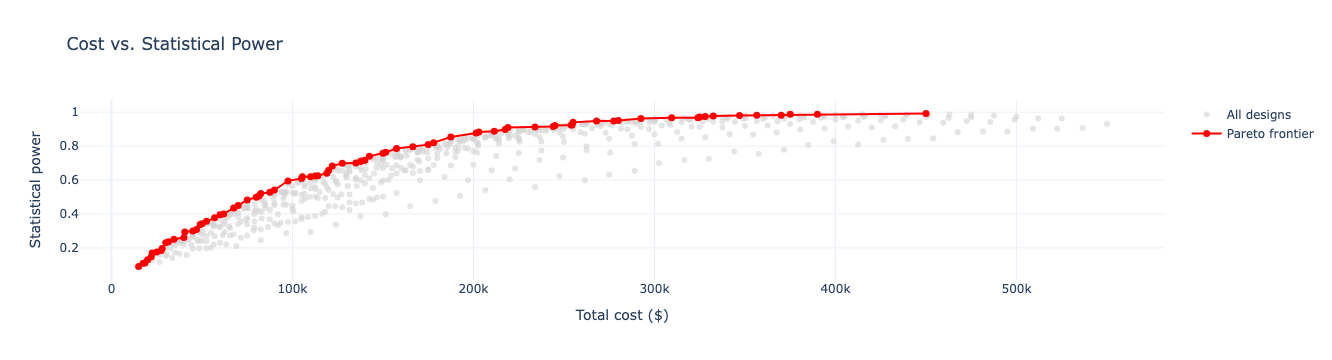

In [79]:

# Interactive plot (requires Plotly)
# If needed, install using: %pip install plotly
import plotly.express as px


# Plot all designs
fig = px.scatter(
    results,
    x="cost",
    y="power",
    hover_data=["n", "p_target", "n_treated", "n_control"],
    labels={
        "cost": "Total cost ($)",
        "power": "Statistical power"
    },
    title="Cost vs. Statistical Power",
    color_discrete_sequence=["lightgray"]
)

fig.update_traces(
    marker=dict(size=6, opacity=0.6),
    name="All designs",
    showlegend=True
)

# Highlight Pareto frontier
fig.add_scatter(
    x=frontier["cost"],
    y=frontier["power"],
    mode="lines+markers",
    name="Pareto frontier",
    line=dict(color="red", width=2),
    marker=dict(color="red", size=7),
    customdata=frontier[["n", "p_target", "n_treated", "n_control"]].to_numpy(),
    hovertemplate=(
        "Cost: $%{x:,.0f}<br>"
        "Power: %{y:.3f}<br>"
        "n: %{customdata[0]}<br>"
        "p: %{customdata[1]:.2f}<br>"
        "Treated: %{customdata[2]}<br>"
        "Control: %{customdata[3]}"
        "<extra></extra>"
    )
)

fig.update_layout(
    xaxis_title="Total cost ($)",
    yaxis_title="Statistical power",
    legend_title_text="",
    template="plotly_white"
)

fig.show()


# Part 3B - Prioritizing designs
How should we choose which designs to evaluate? We'll compare two strategies:

- **Random sampling:** Select 50 designs at random.
- **Analytical guidance:** Use the simpler analytical power formula from Part 1 to prioritize promising designs, even though its estimates are imperfect.

Can an imperfect analytical model help us make better use of a limited simulation budget?

In [66]:
# first define a function that returns the simple analytical power
def analytical_power(n,p):
    n_treated = int(n * p)
    n_control = n - n_treated

    # Notice we don't use SD_TREATED, SD_CONTROL
    se = SD_SIMPLE * np.sqrt((1/(n_treated)) + (1/(n_control)))

    alpha = 1.0-CONFIDENCE
    z_critical = norm.ppf(1 - alpha / 2)
    threshold = z_critical * se
    
    power = (
        norm.cdf(-threshold, loc=BETA, scale=se)
        + 1.0-norm.cdf(threshold, loc=BETA, scale=se)
    )

    return power


In [73]:
# constraints to filter the original grid - uncomment some additional constrains to see observe the impact
constraints = (
    grid['n'] > 0
    # & (grid['n'] <= 500)
    # & (grid['n_treated'] <= 300)
)

filtered_grid = grid[constraints].copy()

# Suppose we can only 'afford' to simulate 50 designs
# Two ways to select from the original 630 designs: random vs. using simple analytical power
N_DESIGNS = 50

# random N_DESIGNS configurations (n,p)
random_grid = filtered_grid.sample(n=N_DESIGNS, replace=True)

# compute simple power for all design configurations
filtered_grid["simple_power"] = results.apply(
    lambda row: analytical_power(row['n'],row['p_target']),
    axis=1
)

# sort designs by value of simple power; highest to lowest, and pick top N_DESIGNS
ranked_grid = filtered_grid.sort_values(by='simple_power', ascending=False).head(N_DESIGNS)

In [74]:
results_random_grid = random_grid.copy()
results_ranked_grid = ranked_grid.copy()

for r in [results_random_grid, results_ranked_grid]:
    r["power"] = r.apply(
        lambda row: simulate_power(
            int(row["n_treated"]),
            int(row["n_control"]),
            BETA, BASELINE, SD_CONTROL, SD_TREATED,
            CONFIDENCE, 4000, rng
        ),
        axis=1
    )

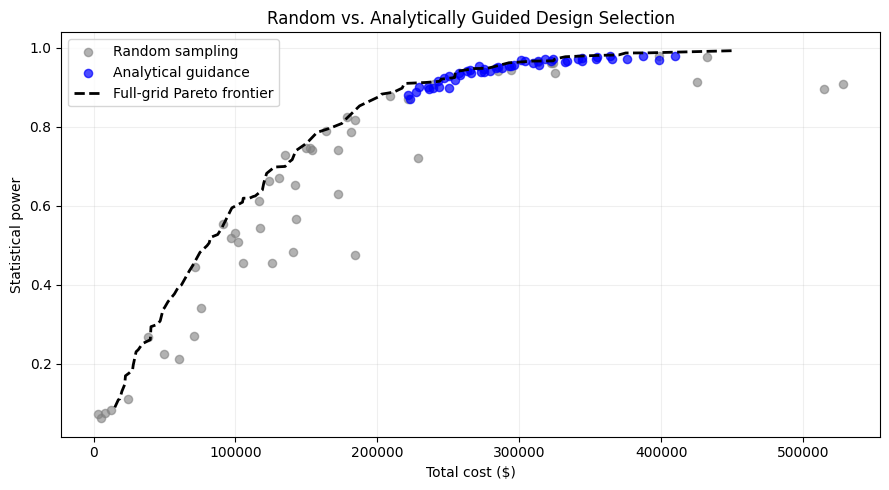

In [81]:
# Compare random sampling vs. analytical guidance
plt.figure(figsize=(9, 5))

plt.scatter(
    results_random_grid["cost"], results_random_grid["power"],
    color="gray", alpha=0.6, s=35, label="Random sampling"
)

plt.scatter(
    results_ranked_grid["cost"], results_ranked_grid["power"],
    color="blue", alpha=0.7, s=35, label="Analytical guidance"
)

plt.plot(
    frontier["cost"], frontier["power"],
    color="black", linestyle="--", linewidth=2,
    label="Full-grid Pareto frontier"
)

plt.xlabel("Total cost ($)")
plt.ylabel("Statistical power")
plt.title("Random vs. Analytically Guided Design Selection")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Takeaway

- Even an imperfect analytical model can help us prioritize which designs to evaluate through simulation.
- Analytically guided designs are more likely to lie near the cost–power frontier than randomly selected designs.